# 03 · Managing risk: limits, bad days and what to do about them

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/03_risk_limits_one_asset.ipynb)

*QM FinTech Society quant workshop · Led by **Adnan Salehin** (Lead SWE & VP, JPMorgan)*

Notebook 01 measured how far a fund can fall. This notebook asks the next question: **what would you do about it?** An investor rarely says "set my value at risk to 3%". They say *"I never want to lose more than a sixth of my money."* We turn sentences like that into numbers, estimate how bad a bad day can be, and test three ways to react to a crash. Still **one asset** (SPY) and **no strategy**: the only decision is how to respond to losses.

**What you'll do (~60 min):**
1. Write an investor's limits in plain English and count how often SPY broke them
2. Turn limits into earlier **warning lines**
3. Estimate a bad day with **value at risk** and check whether it can be trusted
4. Compare three reactions to a crash: **hold**, **sell and stay out**, and **sell and come back**
5. See what limits cannot do

Cells marked **✏️ Try it** are for you to edit and re-run.

> **Running in Google Colab?** If Colab warns that this notebook wasn't written by Google, click **Run anyway**. Then use **File → Save a copy in Drive** so your changes are kept.

## Setup

Run this cell first. In Google Colab it downloads the workshop code and price data from GitHub; on a laptop it simply finds them.

In [1]:
import os, subprocess, sys

REPO = "qm-fintech-quant-workshop"
if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", f"https://github.com/kolyamkl/{REPO}.git"], check=True)
    os.chdir(REPO)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)

## 1. An investor's limits, in their own words

Imagine an investor who owns SPY and says:

> *"Never let me fall more than **15%** below my highest value, and never let me lose more than **3%** in a single day."*

Those are two **limits**: one on the drawdown from notebook 01 and one on a single day's loss. We look at 2019 to 2023, a period with a crash in it.

**Predict first:** out of about 1,150 trading days, how many do you think SPY lost more than 3%? And on how many days was it more than 15% below its peak? Write down both guesses, then run the cell.

In [2]:
from backtester import load_closes, risk
from backtester.metrics import drawdown_series

closes = load_closes(["SPY"], start="2019-06-01", end="2023-12-31")
spy_returns = closes["SPY"].pct_change().dropna()
value = (1 + spy_returns).cumprod()
fall = drawdown_series(value)

print(f"Days with a loss of more than 3%:  {(spy_returns <= -0.03).sum()} of {len(spy_returns)}")
print(f"Days more than 15% below the peak: {(fall <= -0.15).sum()} of {len(fall)}")

Days with a loss of more than 3%:  24 of 1153
Days more than 15% below the peak: 197 of 1153


Losing 3% in a day is rare, and a 15% fall was hit on a large share of all days. Buy and hold breaks the drawdown limit for long stretches, so the investor needs a rule for what to do. That rule is a **risk manager**.

## 2. From limits to warning lines

By the time a limit is hit, it is too late to act: the damage is done, and you can only react at the next close. So the risk manager watches **earlier warning lines**, worked out from the limits:

| Line | Value | What happens |
|---|---|---|
| Rotate line | half the drawdown limit | start reducing risk |
| Emergency line | 80% of the drawdown limit | cut hard |
| Daily loss line | the daily limit | a day this bad is a trigger by itself |
| Value at risk budget | the daily limit | keep the expected bad day inside the limit |

`Limits` holds the investor's two numbers, and `lines_from_limits` works out the rest.

In [3]:
limits = risk.Limits(max_drawdown=0.15, max_daily_loss=0.03)
risk.lines_from_limits(limits)

Lines(rotate_at=0.075, emergency_at=0.12, var_budget=0.03, shock_day=0.03)

## 3. How bad is a bad day? Value at risk

**Value at risk (VaR)** answers: *"on a bad day, how much could I lose?"* The **99% one-day VaR** is the loss that should be beaten on only 1 day in 100. A VaR of 3% says: expect to lose 3% or more on about one day in a hundred.

There are two ways to estimate it:
- **From a formula.** Assume returns follow a bell curve and use `2.326 × the daily standard deviation`. 2.326 is where the 99% point of a bell curve sits.
- **From history.** Sort every past day and read off the loss that only 1% of days were worse than.

A third number, **expected shortfall**, answers *"when it is that bad, how bad is it on average?"* It is the average loss on the days beyond the VaR.

We compute all three on the **same days**, so any difference is real:

In [4]:
pd.Series({
    "99% one-day VaR from the formula": 2.326 * spy_returns.std(),
    "99% one-day VaR read from history": risk.historical_var(spy_returns),
    "Average loss on the worst 1% of days": risk.expected_shortfall(spy_returns),
}).map("{:.2%}".format).to_frame("SPY, 2019 to 2023")

,"SPY, 2019 to 2023"
99% one-day VaR from the formula,3.16%
99% one-day VaR read from history,3.74%
Average loss on the worst 1% of days,5.79%


History says the bad days were worse than the bell-curve formula expects, and the average of the worst days is worse again. Real markets have **fat tails**: extreme days happen more often than a bell curve says.

A risk manager can only use what was known **before** today, so the real test is: *if I use the last 60 days to forecast today's VaR, how often does today's loss beat it?* It should be about 1 day in 100. The cell uses yesterday's forecast for today's loss, so it does not peek.

In [5]:
forecast = (2.326 * spy_returns.rolling(60).std()).shift(1)
beaten = (spy_returns < -forecast).dropna()
print(f"Days the 60-day VaR forecast was beaten: {beaten.sum()} of {len(beaten)} ({beaten.mean():.1%}). The target is 1.0%.")
beaten.groupby(beaten.index.to_period("Q")).sum().sort_values(ascending=False).head(4).to_frame("days beaten")

Days the 60-day VaR forecast was beaten: 27 of 1153 (2.3%). The target is 1.0%.


,days beaten
Date,
2020Q1,11
2020Q3,2
2021Q3,2
2021Q4,2


The forecast fails more than it should, and the failures come in clumps, in the weeks of the 2020 crash. VaR looks backwards at calm days, so it is at its **lowest just before a crash begins**. It is a useful alarm and a poor guarantee.

## 4. Three ways to react to a crash

We replay 2019 to 2023 day by day. At each close the code checks the warning lines. When one is crossed, the risk manager decides what to do. Trades are made at the **next** close and pay a cost (5 bp). Money sitting in cash earns **3% a year** in all three runs, so none of them is flattered or punished by the cash assumption.

1. **Buy and hold:** do nothing, ever.
2. **Sell and stay out:** on the first real loss past a line, sell everything and stay in cash for good.
3. **Sell and come back:** the same sale, but after 60 trading days (about three months) in cash, buy SPY back, whatever the market did.

*(The replay takes a few seconds.)*

In [6]:
start = {"SPY": 1.0}
hold = risk.run_guarded(closes, start, limits, manager=None, calm=[], name="Buy and hold", cash_rate=0.03)
stay_out = risk.run_guarded(closes, start, limits, manager=risk.cash_exit_manager, calm=[], name="Sell and stay out", cash_rate=0.03)
come_back = risk.run_guarded(closes, start, limits, manager=risk.exit_and_return_manager, calm=[], name="Sell and come back", cash_rate=0.03)
risk.compare([hold, stay_out, come_back])

,Buy and hold,Sell and stay out,Sell and come back
Total return,78.1%,27.1%,55.7%
Annual return (CAGR),14.2%,5.7%,10.8%
Annual volatility,21.9%,3.7%,11.7%
Sharpe ratio,0.58,0.71,0.68
Max drawdown,-33.7%,-4.7%,-17.3%
Number of trades,0,1,14
Days over daily limit,23,1,6
Worst day,-10.9%,-3.3%,-5.8%
Costs paid,0.0%,0.1%,0.7%


The picture shows when each reaction fired. The red dashed line is the investor's 15% limit.

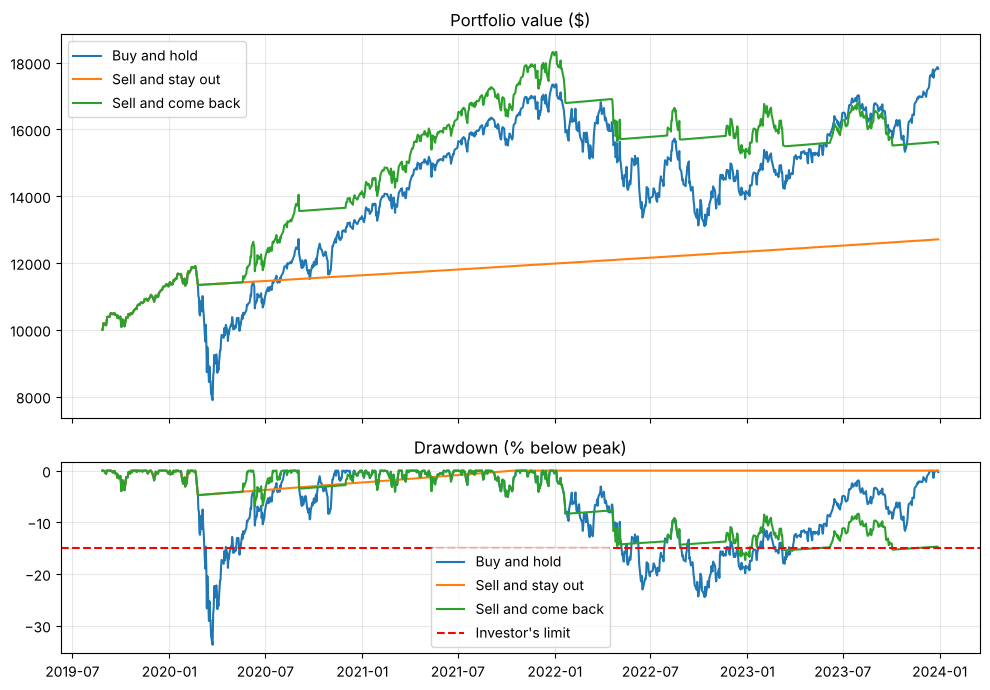

In [7]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for result in (hold, stay_out, come_back):
    top.plot(result.equity.index, result.equity, label=result.name)
    bottom.plot(result.equity.index, drawdown_series(result.equity) * 100, label=result.name)
bottom.axhline(-limits.max_drawdown * 100, color="red", linestyle="--", label="Investor's limit")
top.set_title("Portfolio value ($)"); bottom.set_title("Drawdown (% below peak)")
top.legend(); bottom.legend(); top.grid(alpha=0.3); bottom.grid(alpha=0.3)
fig.tight_layout()
plt.show()

And inside the two crises from notebook 01:

In [8]:
risk.crisis_table({r.name: r.equity for r in (hold, stay_out, come_back)})

Return Worst fall
Crisis           Portfolio                            
2020 Covid crash Buy and hold          1.1%     -33.7%
                 Sell and stay out    -3.4%      -4.7%
                 Sell and come back   11.7%      -7.0%
2022 bear market Buy and hold        -18.6%     -24.5%
                 Sell and stay out     3.0%       0.0%
                 Sell and come back  -16.0%     -17.3%

**Read the table honestly:**
- **Sell and stay out** kept the drawdown inside the 15% limit, and by a wide margin. It also earned far less than buy and hold, because it sat in cash through the whole recovery. It never came back.
- **Sell and come back** earned much more, because it was back in time for the rebound. But it **did not stay inside the 15% limit**: coming back means taking risk again, and a second fall can arrive.
- **No reaction is free.** Each one trades return for safety at a different exchange rate. The Sharpe ratio, which measures return per unit of risk, is the fairest single number to compare them, but only the investor can say how much a 15% limit is worth.
- Which is best depends on *when* in the crash the portfolio sold and when it bought back. With a different start date the order could change. That is a reason to test on several periods, as in notebook 02.

Every decision is logged with its reason. This is what an investor should be able to read:

In [9]:
pd.set_option("display.max_colwidth", 120)
come_back.log[["date", "trigger", "reasons", "action", "turnover"]].head(8)

,date,trigger,reasons,action,turnover
0,2020-02-24,rotate,Today's loss of -3.3% is beyond the daily limit of -3.0%.,all cash,1.0
1,2020-05-19,NaN,60 trading days in cash.,back in,1.0
2,2020-05-28,rotate,One-day VaR 8.69% is above the 3.00% budget.,hold,NaN
3,2020-06-05,rotate,One-day VaR 7.92% is above the 3.00% budget.,hold,NaN
4,2020-06-15,rotate,One-day VaR 5.88% is above the 3.00% budget.,hold,NaN
5,2020-06-23,rotate,One-day VaR 4.62% is above the 3.00% budget.,hold,NaN
6,2020-07-01,rotate,One-day VaR 3.93% is above the 3.00% budget.,hold,NaN
7,2020-07-10,rotate,One-day VaR 3.68% is above the 3.00% budget.,hold,NaN


## 5. What limits cannot do

- **Gaps.** The rules look at the close and trade at the next close. If the market falls 10% in a day, nothing can act in between. Look at the *Worst day* row.
- **Limits are targets, not guarantees.** Anyone selling a "guaranteed" stop-loss is selling something that cannot exist, because a price can jump past any level.
- **Forecasts fail when you need them.** VaR was too low in March 2020 because February was calm.
- **A risk rule is a strategy.** "Sell and stay out" is a strategy with its own return and its own way to fail. It deserves the same honest testing as any other.

## 6. ✏️ Your turn

1. Tighten the limits to `risk.Limits(max_drawdown=0.10, max_daily_loss=0.02)` and re-run section 4. How many more trades? How much more cost?
2. Set `risk.STAY_OUT_DAYS = 120` and re-run. Does waiting longer help or hurt?
3. Set `cash_rate=0` in the three runs. How does the ranking change?

**Check yourself:**
- Why do we set warning lines below the limits instead of acting at the limit?
- A bank tells you its 99% VaR is 2%. What does that mean, and what does it not tell you?
- If "sell and stay out" has the smallest fall, why would anyone choose anything else?

> Educational use only. Simulated results on historical data; not financial advice.

### Next: your first strategies

You now have the tools to judge a strategy honestly: costs, a later test period, sample size, a fair benchmark, and risk limits. Time to test one.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/04_first_strategy_ma_crossover.ipynb) `04_first_strategy_ma_crossover.ipynb`